Classifier: Multinomial Naive Bayes
F1 Score: 0.7262921111819256
Recall: 0.771491192466921
Accuracy: 0.771491192466921
Precision: 0.6898809683344294
Confusion Matrix:
[[4362  547    0]
 [ 855 5142    1]
 [ 997  415    0]]



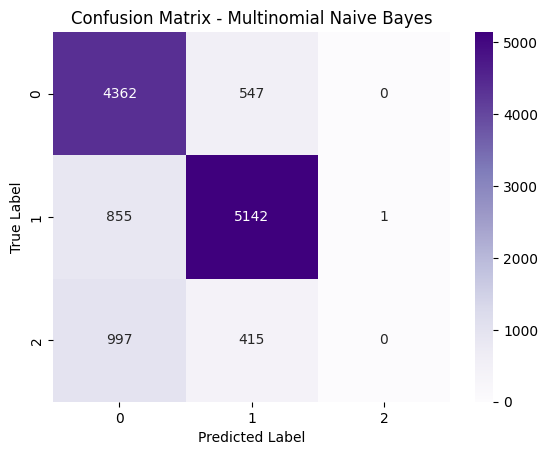

Classifier: Logistic Regression
F1 Score: 0.7580566441045353
Recall: 0.7911356441269584
Accuracy: 0.7911356441269584
Precision: 0.7541832236700031
Confusion Matrix:
[[4398  440   71]
 [ 650 5254   94]
 [ 867  451   94]]



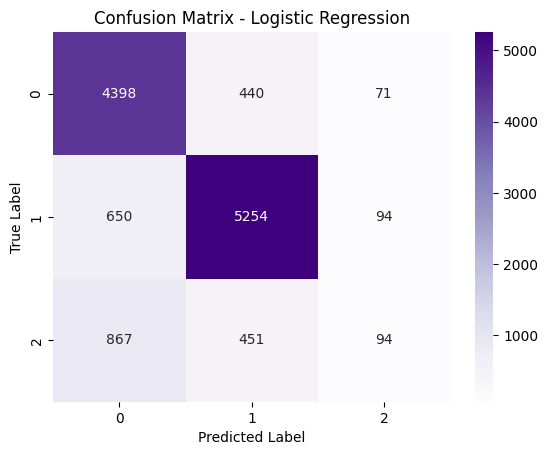

Classifier: Support Vector Machine
F1 Score: 0.7518919324766937
Recall: 0.7958438184917607
Accuracy: 0.7958438184917607
Precision: 0.7533285972046574
Confusion Matrix:
[[4501  396   12]
 [ 693 5285   20]
 [ 951  443   18]]



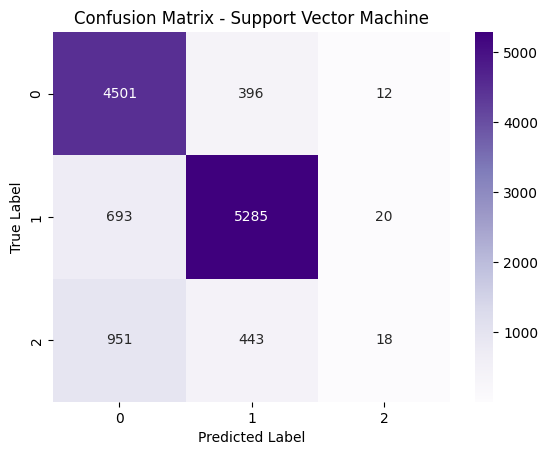

Classifier: Random Forest
F1 Score: 0.7235732273713104
Recall: 0.7681630002435262
Accuracy: 0.7681630002435262
Precision: 0.6881943419603673
Confusion Matrix:
[[4360  541    8]
 [ 893 5103    2]
 [1003  409    0]]



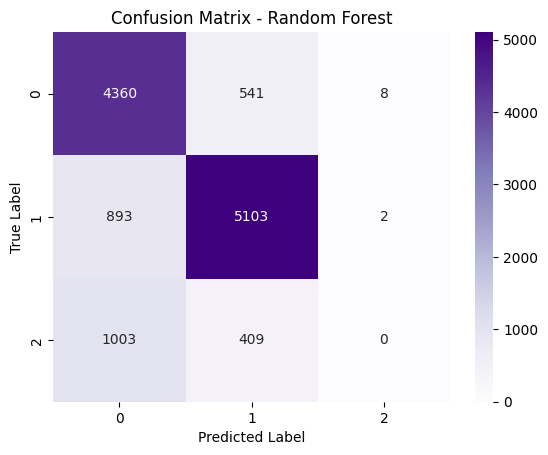

Best Classifier based on Accuracy: Support Vector Machine


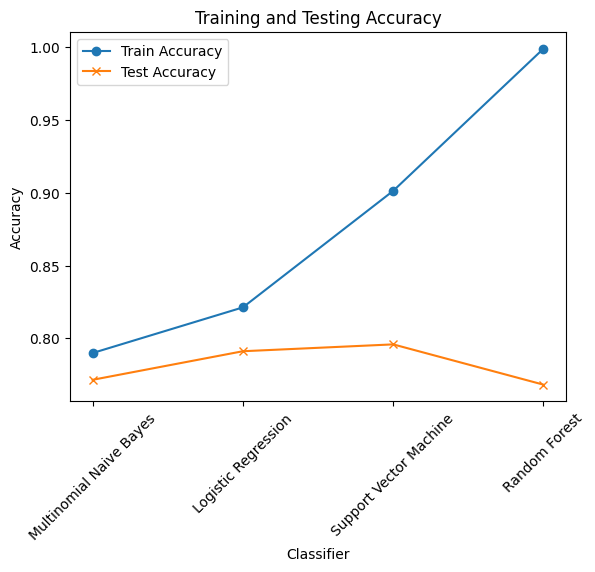

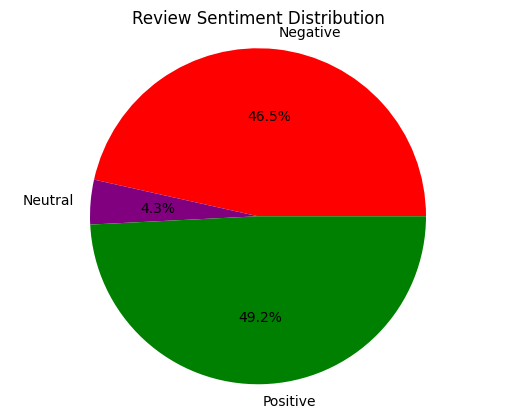

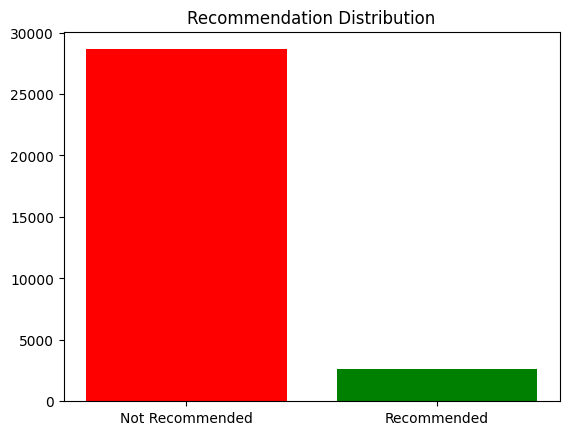

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from collections import Counter
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Load the dataset
data = pd.read_csv('/content/sample_data/spotifyappreviews.csv')

# Preprocess the 'Review' column
def preprocess(text):
    # Lowercasing
    text = text.lower()

    # Tokenization
    words = word_tokenize(text)

    # Removing stopwords
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words]

    # Join the words back to form the preprocessed text
    preprocessed_text = " ".join(words)
    return preprocessed_text

data['Review'] = data['Review'].apply(preprocess)

# Split the data into features (X) and target (y)
X = data['Review']
y = data['Rating'].apply(lambda x: 1 if x > 3 else (0 if x < 3 else 2))  # Positive: 1, Negative: 0, Neutral: 2

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Text vectorization
vectorizer = TfidfVectorizer()  # You can also use CountVectorizer if you prefer
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

# Define classifiers
classifiers = [
    ('Multinomial Naive Bayes', MultinomialNB()),
    ('Logistic Regression', LogisticRegression(max_iter=500)),
    ('Support Vector Machine', SVC()),
    ('Random Forest', RandomForestClassifier())
]

# Train and evaluate classifiers
train_accuracy = []
test_accuracy = []
best_accuracy = 0
best_classifier_name = None
best_classifier = None

for name, clf in classifiers:
    clf.fit(X_train_vectorized, y_train)
    y_pred_train = clf.predict(X_train_vectorized)
    y_pred_test = clf.predict(X_test_vectorized)

    train_accuracy.append(accuracy_score(y_train, y_pred_train))
    test_accuracy.append(accuracy_score(y_test, y_pred_test))

    print(f"Classifier: {name}")
    print(f"F1 Score: {f1_score(y_test, y_pred_test, average='weighted')}")
    print(f"Recall: {recall_score(y_test, y_pred_test, average='weighted')}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred_test)}")
    print(f"Precision: {precision_score(y_test, y_pred_test, average='weighted')}")
    cm = confusion_matrix(y_test, y_pred_test)
    print(f"Confusion Matrix:\n{cm}\n")

    # Plot confusion matrix with numbers using seaborn heatmap
    plt.figure()
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Purples, ax=ax)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title(f'Confusion Matrix - {name}')
    plt.show()

    if accuracy_score(y_test, y_pred_test) > best_accuracy:
        best_accuracy = accuracy_score(y_test, y_pred_test)
        best_classifier_name = name
        best_classifier = clf

# Print the best classifier
print(f"Best Classifier based on Accuracy: {best_classifier_name}")

# Training and testing spline graph
plt.plot(range(len(train_accuracy)), train_accuracy, label='Train Accuracy', marker='o')
plt.plot(range(len(test_accuracy)), test_accuracy, label='Test Accuracy', marker='x')
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.xticks(range(len(train_accuracy)), [name for name, _ in classifiers], rotation=45)
plt.legend()
plt.show()

# Apply the best classifier on the whole dataset
best_classifier.fit(vectorizer.transform(X), y)
data['predicted_label'] = best_classifier.predict(vectorizer.transform(X))

# Draw pie chart and bar graph for positive, negative, neutral reviews
review_sentiment_counts = Counter(data['predicted_label'])

labels = ['Negative', 'Neutral', 'Positive']
colors = ['red', 'purple', 'green']
sizes = [review_sentiment_counts[0], review_sentiment_counts[2], review_sentiment_counts[1]]

plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%')
plt.title('Review Sentiment Distribution')
plt.axis('equal')
plt.show()

recommendation_labels = ['Not Recommended', 'Recommended']
recommendation_colors = ['red', 'green']
recommendation_sizes = [review_sentiment_counts[0], review_sentiment_counts[2]]

plt.bar(recommendation_labels, recommendation_sizes, color=recommendation_colors)
plt.title('Recommendation Distribution')
plt.show()

